In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Set global visual style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.size'] = 11

# Load cleaned dataset
df = pd.read_csv('../Data/CleanedData.csv')
df

,Unnamed: 0,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,log_price,sale_year,sale_month,house_age,is_renovated,years_since_renovation,total_rooms,price_per_sqft,living_to_lot_ratio,basement_to_lot_ration
0,0,2014-10-13,221900.0,3.0,1.00,1180,5650,1.0,0,0,...,12.309987,2014,10,59,0,59,4.00,188.050847,0.208850,0.000000
1,1,2014-12-09,538000.0,3.0,2.25,2570,7242,2.0,0,0,...,13.195616,2014,12,63,1,23,5.25,209.338521,0.354874,0.055233
2,2,2015-02-25,180000.0,2.0,1.00,770,10000,1.0,0,0,...,12.100718,2015,2,82,0,82,3.00,233.766234,0.077000,0.000000
3,3,2014-12-09,604000.0,4.0,3.00,1960,5000,1.0,0,0,...,13.311331,2014,12,49,0,49,7.00,308.163265,0.392000,0.182000
4,4,2015-02-18,510000.0,3.0,2.00,1680,8080,1.0,0,0,...,13.142168,2015,2,28,0,28,5.00,303.571429,0.207921,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21607,21608,2014-05-21,360000.0,3.0,2.50,1530,1131,3.0,0,0,...,12.793862,2014,5,5,0,5,5.50,235.294118,1.352785,0.000000
21608,21609,2015-02-23,400000.0,4.0,2.50,2310,5813,2.0,0,0,...,12.899222,2015,2,1,0,1,6.50,173.160173,0.397385,0.000000
21609,21610,2014-06-23,402101.0,2.0,0.75,1020,1350,2.0,0,0,...,12.904461,2014,6,5,0,5,2.75,394.216667,0.755556,0.000000
21610,21611,2015-01-16,400000.0,3.0,2.50,1600,2388,2.0,0,0,...,12.899222,2015,1,11,0,11,5.50,250.000000,0.670017,0.000000


In [2]:

p1, p99 = df['price'].quantile(0.01), df['price'].quantile(0.99)

# Plotly v6+ uses px.scatter_map instead of scatter_mapbox
fig_map = px.scatter_map(
    df,
    lat='lat',
    lon='long',
    color='price',
    size='sqft_living',
    color_continuous_scale='Viridis',
    range_color=[p1, p99],
    zoom=9,
    map_style="open-street-map",  # Loads real OpenStreetMap tiles as background
    title="<b>Real Map: House Locations & Prices (King County)</b>",
    hover_name="price",
    hover_data={
        "bedrooms": True,
        "bathrooms": True,
        "sqft_living": True,
        "grade": True,
        "zipcode": True,
        "lat": False,
        "long": False
    },
    opacity=0.6,
    height=700
)

fig_map.update_layout(margin={"r":0, "t":40, "l":0, "b":0})
fig_map.show()

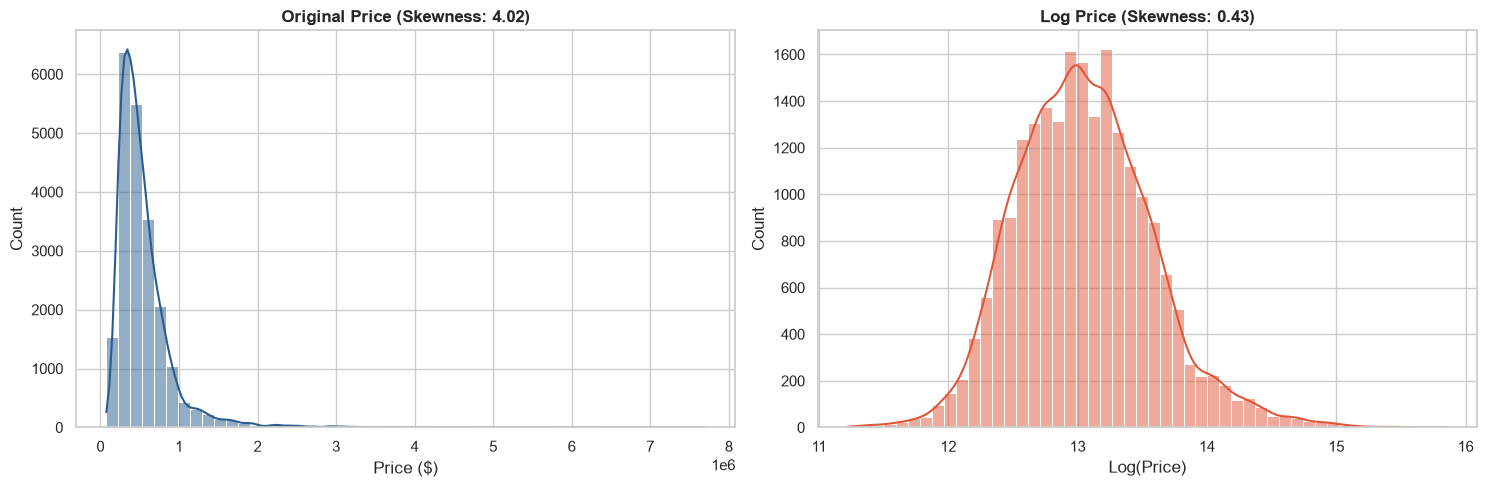

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Original Price
sns.histplot(df['price'], kde=True, ax=axes[0], color='#2b5c8f', bins=50)
axes[0].set_title(f"Original Price (Skewness: {df['price'].skew():.2f})", fontweight='bold')
axes[0].set_xlabel("Price ($)")
axes[0].set_ylabel("Count")

# Log Price
sns.histplot(df['log_price'], kde=True, ax=axes[1], color='#e05638', bins=50)
axes[1].set_title(f"Log Price (Skewness: {df['log_price'].skew():.2f})", fontweight='bold')
axes[1].set_xlabel("Log(Price)")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

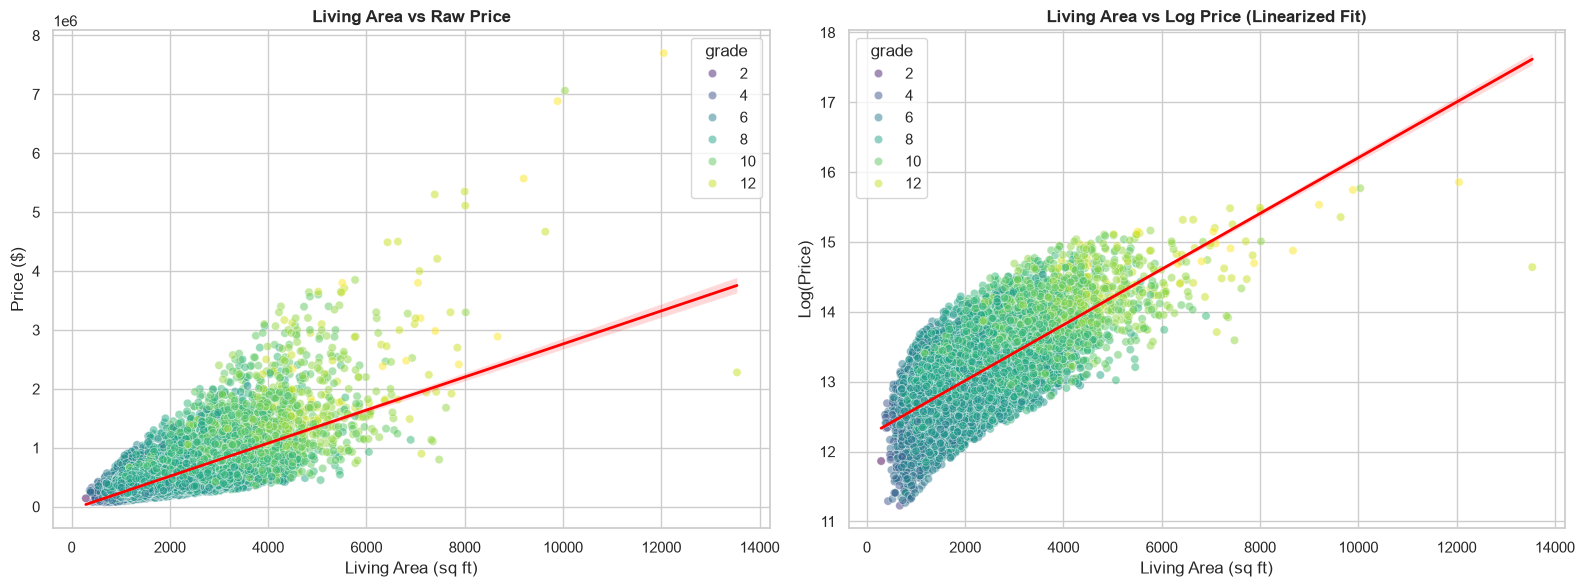

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Living Area vs Raw Price
sns.scatterplot(
    data=df, x='sqft_living', y='price', hue='grade',
    palette='viridis', alpha=0.5, ax=axes[0]
)
sns.regplot(
    data=df, x='sqft_living', y='price', scatter=False,
    ax=axes[0], color='red', line_kws={'linewidth': 2}
)
axes[0].set_title("Living Area vs Raw Price", fontweight='bold')
axes[0].set_xlabel("Living Area (sq ft)")
axes[0].set_ylabel("Price ($)")

# Living Area vs Log Price
sns.scatterplot(
    data=df, x='sqft_living', y='log_price', hue='grade',
    palette='viridis', alpha=0.5, ax=axes[1]
)
sns.regplot(
    data=df, x='sqft_living', y='log_price', scatter=False,
    ax=axes[1], color='red', line_kws={'linewidth': 2}
)
axes[1].set_title("Living Area vs Log Price (Linearized Fit)", fontweight='bold')
axes[1].set_xlabel("Living Area (sq ft)")
axes[1].set_ylabel("Log(Price)")

plt.tight_layout()
plt.show()

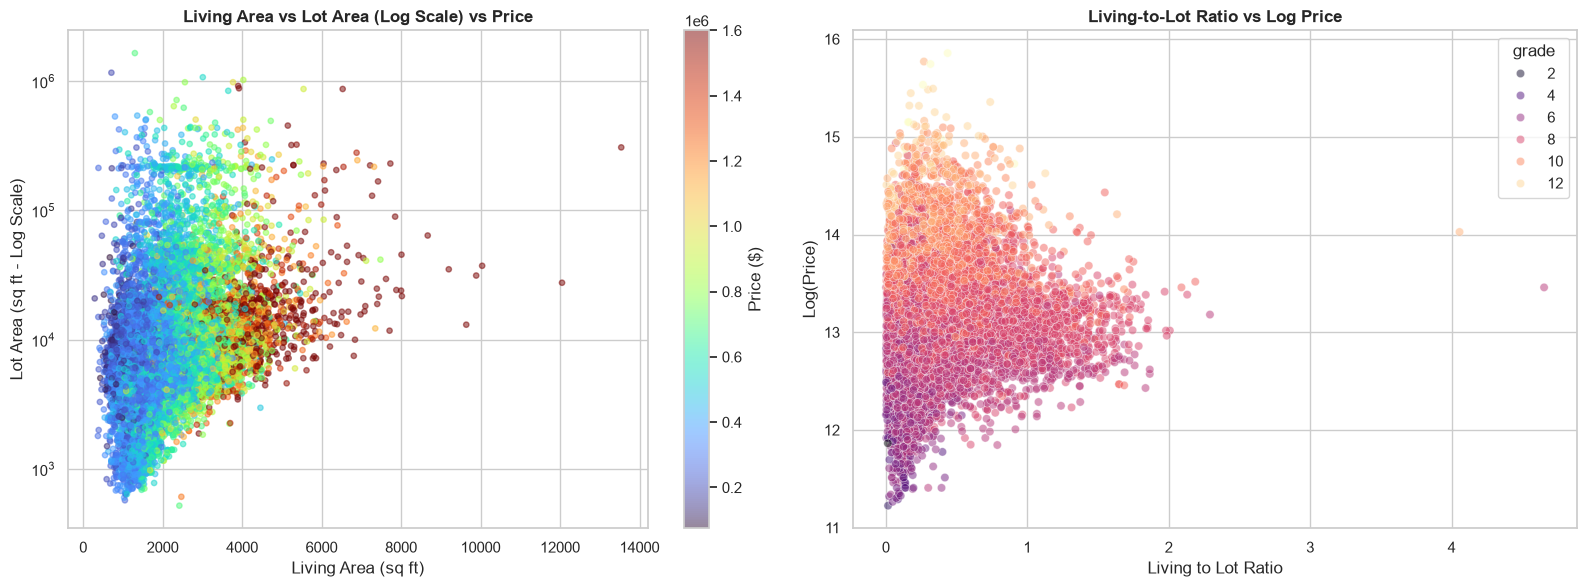

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Living Area vs Lot Area (Log Scale) colored by Price
sc1 = axes[0].scatter(
    df['sqft_living'], df['sqft_lot'],
    c=df['price'], cmap='turbo', alpha=0.5, s=15,
    vmax=df['price'].quantile(0.98)
)
axes[0].set_yscale('log')
axes[0].set_title("Living Area vs Lot Area (Log Scale) vs Price", fontweight='bold')
axes[0].set_xlabel("Living Area (sq ft)")
axes[0].set_ylabel("Lot Area (sq ft - Log Scale)")
fig.colorbar(sc1, ax=axes[0], label="Price ($)")

# 2. Living to Lot Ratio vs Price
sns.scatterplot(
    data=df, x='living_to_lot_ratio', y='log_price',
    hue='grade', palette='magma', alpha=0.5, ax=axes[1]
)
axes[1].set_title("Living-to-Lot Ratio vs Log Price", fontweight='bold')
axes[1].set_xlabel("Living to Lot Ratio")
axes[1].set_ylabel("Log(Price)")

plt.tight_layout()
plt.show()

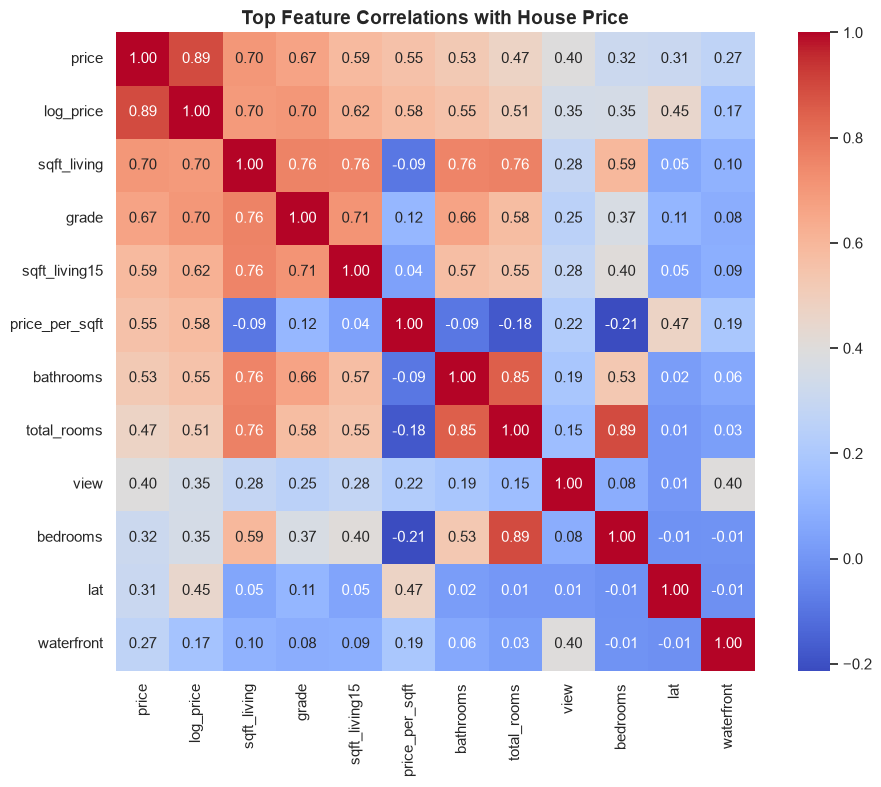

In [6]:
plt.figure(figsize=(10, 8))
numeric_cols = df.select_dtypes(include=[np.number]).columns
top_corr_cols = df[numeric_cols].corr()['price'].abs().nlargest(12).index

corr_matrix = df[top_corr_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True, square=True)
plt.title("Top Feature Correlations with House Price", fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

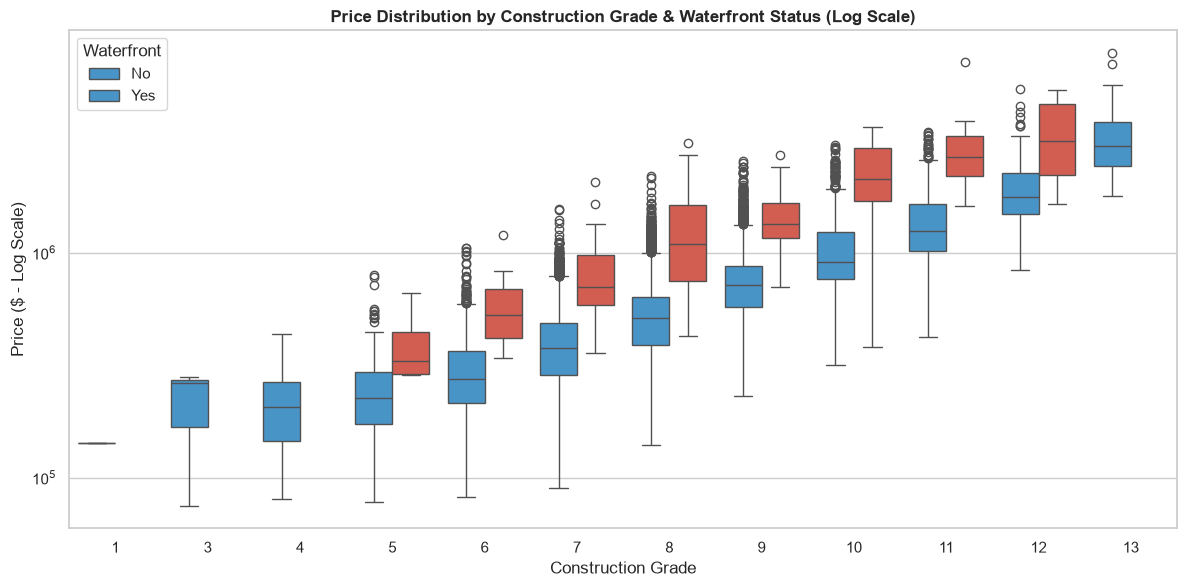

In [7]:
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df, x='grade', y='price', hue='waterfront',
    palette={0: '#3498db', 1: '#e74c3c'}
)
plt.yscale('log')
plt.title("Price Distribution by Construction Grade & Waterfront Status (Log Scale)", fontweight='bold')
plt.xlabel("Construction Grade")
plt.ylabel("Price ($ - Log Scale)")
plt.legend(title="Waterfront", labels=["No", "Yes"])
plt.tight_layout()
plt.show()

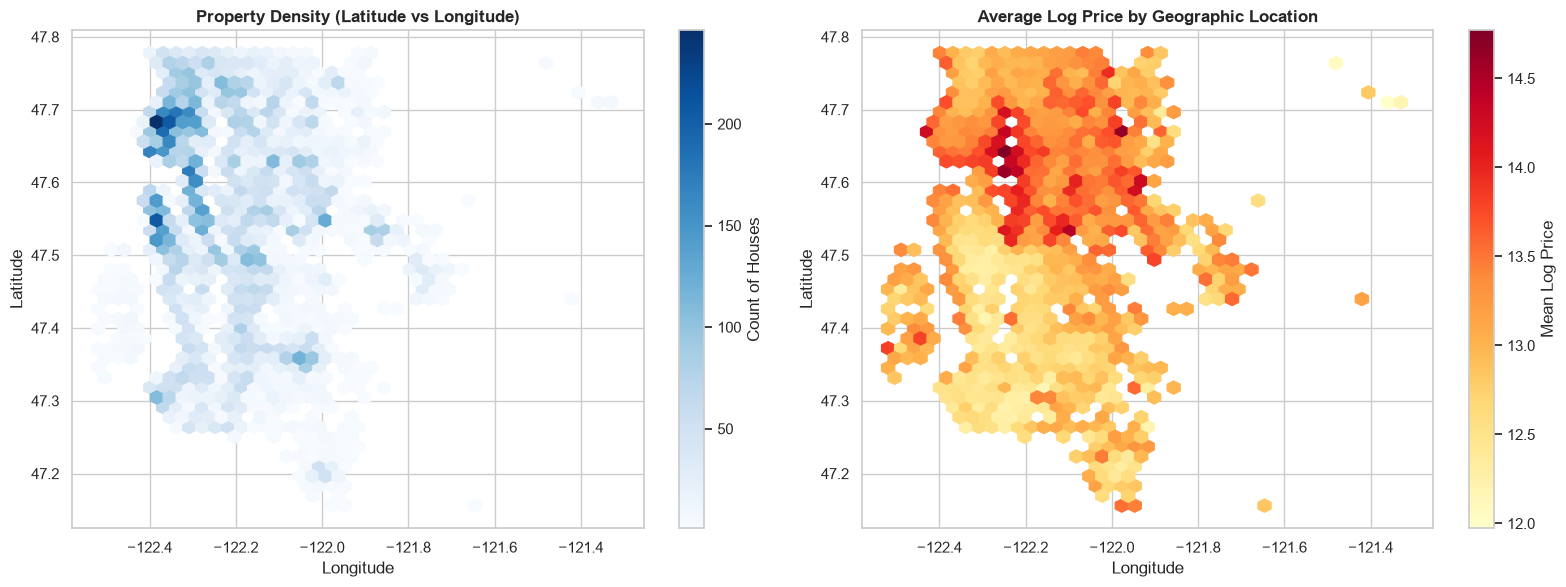

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Spatial Density of Sales
hb1 = axes[0].hexbin(df['long'], df['lat'], gridsize=40, cmap='Blues', mincnt=1)
axes[0].set_title("Property Density (Latitude vs Longitude)", fontweight='bold')
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
fig.colorbar(hb1, ax=axes[0], label="Count of Houses")

# Spatial Average Price
hb2 = axes[1].hexbin(df['long'], df['lat'], C=df['log_price'], gridsize=40, cmap='YlOrRd', reduce_C_function=np.mean)
axes[1].set_title("Average Log Price by Geographic Location", fontweight='bold')
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")
fig.colorbar(hb2, ax=axes[1], label="Mean Log Price")

plt.tight_layout()
plt.show()

In [9]:
fig_3d = px.scatter_3d(
    df.sample(5000, random_state=42), # Subsample for fluid 3D rendering
    x='sqft_living',
    y='grade',
    z='log_price',
    color='price_per_sqft',
    color_continuous_scale='Plasma',
    opacity=0.7,
    title="<b>3D Surface Explorer: Living Area vs Grade vs Log Price</b>"
)
fig_3d.update_layout(height=700)
fig_3d.show()

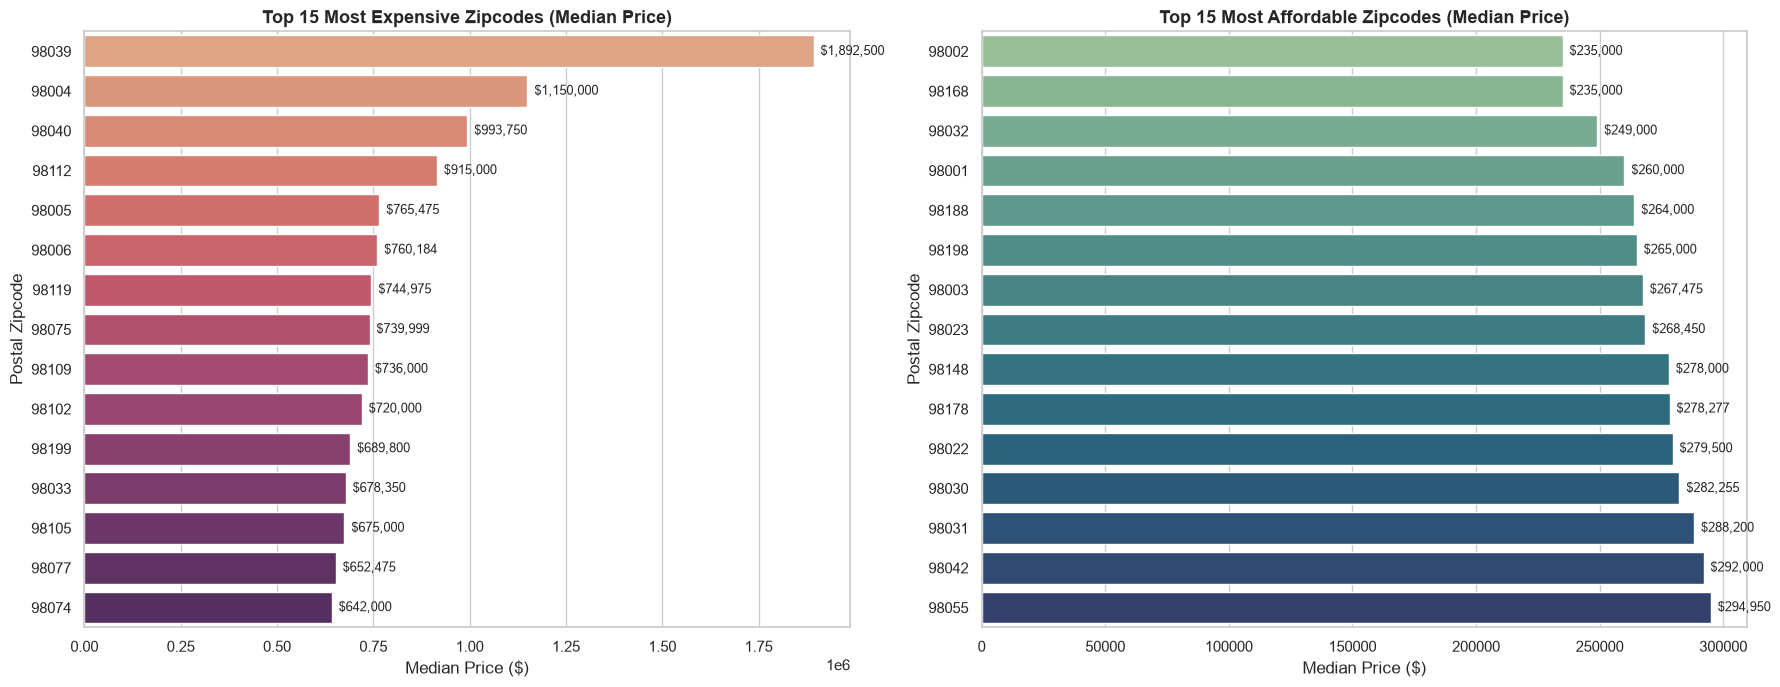

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))


zip_summary = df.groupby('zipcode')['price'].agg(['median', 'count']).reset_index()

# Top 15 Most Expensive Zipcodes
top_15 = zip_summary.sort_values(by='median', ascending=False).head(15).copy()
top_15['zip_str'] = top_15['zipcode'].astype(str)
sns.barplot(
    data=top_15, x='median', y='zip_str', hue='zip_str',
    ax=axes[0], palette='flare', legend=False
)
axes[0].set_title('Top 15 Most Expensive Zipcodes (Median Price)', fontweight='bold', fontsize=13)
axes[0].set_xlabel('Median Price ($)')
axes[0].set_ylabel('Postal Zipcode')
for p in axes[0].patches:
    width = p.get_width()
    axes[0].annotate(f'${width:,.0f}', (width, p.get_y() + p.get_height() / 2.),
                     ha='left', va='center', xytext=(5, 0), textcoords='offset points', fontsize=9)

# Top 15 Most Affordable Zipcodes
bottom_15 = zip_summary.sort_values(by='median', ascending=True).head(15).copy()
bottom_15['zip_str'] = bottom_15['zipcode'].astype(str)
sns.barplot(
    data=bottom_15, x='median', y='zip_str', hue='zip_str',
    ax=axes[1], palette='crest', legend=False
)
axes[1].set_title('Top 15 Most Affordable Zipcodes (Median Price)', fontweight='bold', fontsize=13)
axes[1].set_xlabel('Median Price ($)')
axes[1].set_ylabel('Postal Zipcode')
for p in axes[1].patches:
    width = p.get_width()
    axes[1].annotate(f'${width:,.0f}', (width, p.get_y() + p.get_height() / 2.),
                     ha='left', va='center', xytext=(5, 0), textcoords='offset points', fontsize=9)

plt.tight_layout()
plt.show()
